Optimized UAV Path:
[ 5.  5. 10.]
[ 0.         22.52512071  9.12605414]
[ 0.05919615 39.63105907  9.76874824]
[ 1.5055157  54.40653097  7.95914692]
[23.07220687 68.12564309  8.80113722]
[56.36619873 81.55289461 17.24640365]
[95. 95. 30.]
Best Fitness: 260.16000025998306


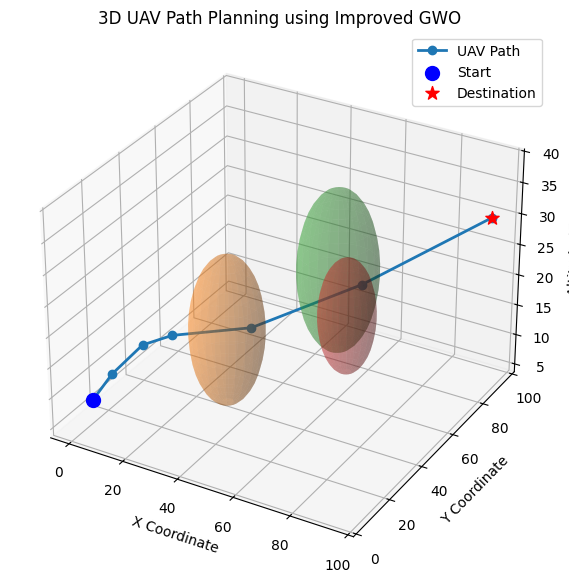

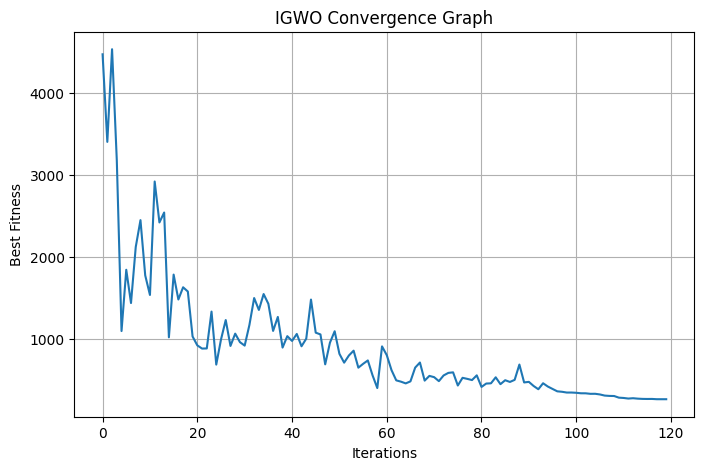

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Starting and destination points
START = np.array([5, 5, 10])
GOAL = np.array([95, 95, 30])

# Parameters
N = 35
MAX_ITER = 120
WAYPOINTS = 5

LOWER = np.array([0, 0, 5])
UPPER = np.array([100, 100, 60])

# Obstacles: x, y, z, radius
OBSTACLES = [
    (35, 35, 18, 12),
    (60, 60, 25, 13),
    (76, 38, 25, 9)
]

# Create complete path
def create_path(position):
    middle = position.reshape(WAYPOINTS, 3)
    return np.vstack((START, middle, GOAL))


# Fitness function
def fitness(position):
    path = create_path(position)

    # Calculate total path length
    length = 0
    for i in range(len(path) - 1):
        length += np.linalg.norm(path[i + 1] - path[i])

    # Obstacle collision penalty
    penalty = 0

    for i in range(len(path) - 1):
        p1 = path[i]
        p2 = path[i + 1]

        for t in np.linspace(0, 1, 12):
            point = p1 + t * (p2 - p1)

            for ox, oy, oz, radius in OBSTACLES:
                center = np.array([ox, oy, oz])
                distance = np.linalg.norm(point - center)

                if distance < radius + 3:
                    penalty += (radius + 3 - distance) ** 2

    # Smoothness penalty
    smoothness = np.sum(np.diff(path, n=2, axis=0) ** 2)

    # Total fitness
    return length + 5000 * penalty + 0.15 * smoothness


# Initialize wolves
def GWO():

    dimension = WAYPOINTS * 3

    wolves = np.random.uniform(
        np.tile(LOWER, WAYPOINTS),
        np.tile(UPPER, WAYPOINTS),
        (N, dimension)
    )

    history = []

    for iteration in range(MAX_ITER):

        scores = np.array([fitness(w) for w in wolves])

        # Select Alpha, Beta and Delta
        order = np.argsort(scores)

        alpha = wolves[order[0]].copy()
        beta = wolves[order[1]].copy()
        delta = wolves[order[2]].copy()

        # Nonlinear convergence factor (illustrative)
        progress = (iteration + 1) / MAX_ITER
        a = 2 * (1 - progress ** 2)

        new_wolves = wolves.copy()

        for i in range(N):

            X = wolves[i]

            # Alpha position update
            r1 = np.random.rand(dimension)
            r2 = np.random.rand(dimension)

            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = np.abs(C1 * alpha - X)
            X1 = alpha - A1 * D_alpha

            # Beta position update
            r1 = np.random.rand(dimension)
            r2 = np.random.rand(dimension)

            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = np.abs(C2 * beta - X)
            X2 = beta - A2 * D_beta

            # Delta position update
            r1 = np.random.rand(dimension)
            r2 = np.random.rand(dimension)

            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = np.abs(C3 * delta - X)
            X3 = delta - A3 * D_delta

            # Weighted position updating
            new_position = (
                0.5 * X1 +
                0.3 * X2 +
                0.2 * X3
            )

            # Keep positions within boundaries
            new_wolves[i] = np.clip(
                new_position,
                np.tile(LOWER, WAYPOINTS),
                np.tile(UPPER, WAYPOINTS)
            )

        wolves = new_wolves

        best_score = min(fitness(w) for w in wolves)
        history.append(best_score)

    # Find best solution
    scores = np.array([fitness(w) for w in wolves])
    best = wolves[np.argmin(scores)]

    return create_path(best), min(scores), history


# Run algorithm
np.random.seed(7)

best_path, best_score, history = GWO()

print("Optimized UAV Path:")

for point in best_path:
    print(point)

print("Best Fitness:", best_score)


# Draw 3D graph
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Optimized path
ax.plot(
    best_path[:, 0],
    best_path[:, 1],
    best_path[:, 2],
    marker='o',
    linewidth=2,
    label="UAV Path"
)

# Start and destination
ax.scatter(*START, color='blue', s=100, label="Start")
ax.scatter(*GOAL, color='red', s=100, marker='*', label="Destination")

# Draw spherical obstacles
u = np.linspace(0, 2 * np.pi, 25)
v = np.linspace(0, np.pi, 20)

for ox, oy, oz, radius in OBSTACLES:

    x = ox + radius * np.outer(np.cos(u), np.sin(v))
    y = oy + radius * np.outer(np.sin(u), np.sin(v))
    z = oz + radius * np.outer(np.ones(len(u)), np.cos(v))

    ax.plot_surface(x, y, z, alpha=0.3)

ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
ax.set_zlabel("Altitude (Z)")

ax.set_title("3D UAV Path Planning using Improved GWO")
ax.legend()

plt.show()


# Convergence graph
plt.figure(figsize=(8, 5))

plt.plot(history)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("IGWO Convergence Graph")

plt.grid()
plt.show()